# Pretraining and training loss curves

Encoder-training curves for the four backbones behind the noiseless $N=6517$ results.

Curves are read from the TensorBoard logs: with `save_best_epoch: true` the
checkpoint is written only when validation improves, so the loss arrays stored inside it are
truncated at the best epoch.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import glob
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import scienceplots
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

plt.style.use(("science", "no-latex"))
%matplotlib inline

SKATR  = "/pfs/10/work/hd_pt254-skatr/skatr"
FIGDIR = "/pfs/10/work/hd_pt254-skatr/paper/figures_revision"
os.makedirs(FIGDIR, exist_ok=True)

cmap = plt.get_cmap("Blues_r")
truth_color = "#1A1A1A"

MODELS = [
    ("SKATR",            "runs/pretraining_transfer_ds/2026-04-01_19-13-48_NoAmp", "firebrick"),
    ("ViT(21cmFAST)",    "runs/supervised/vit_21cmfast_noAugment_3816814",         cmap(0.55)),
    ("ViT(Loreli)",      "runs/supervised/vit_loreli_N6517_zfull_noAug_3973822",   cmap(0.25)),
    ("ViT(Loreli, R+R)", "runs/supervised/vit_loreli_N6517_zfull_RR_3976726",      "mediumaquamarine"),
]

def load(run_dir):
    ev = glob.glob(os.path.join(SKATR, run_dir, "*tfevents*"))[0]
    ea = EventAccumulator(ev, size_guidance={"scalars": 0}); ea.Reload()
    return {t: np.array([s.value for s in ea.Scalars(t)])
            for t in ("epoch_loss_train", "epoch_loss_val")}

curves = [(label, load(path), color) for label, path, color in MODELS]

for label, tb, _ in curves:
    v, t = tb["epoch_loss_val"], tb["epoch_loss_train"]
    i = int(v.argmin())
    print(f"{label:<18} best epoch {i+1:>3}/{v.size}   val {v[i]:.4g}   "
          f"train {t[i]:.4g}   val/train {v[i]/t[i]:.1f}")

E0000 00:00:1793008526.960531 2147074 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793008527.097048 2147074 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793008528.073488 2147074 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793008528.073550 2147074 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793008528.073553 2147074 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793008528.073555 2147074 computation_placer.cc:177] computation placer already registered. Please check linka

SKATR              best epoch  90/100   val 0.3661   train 0.3657   val/train 1.0
ViT(21cmFAST)      best epoch  53/100   val 0.01138   train 0.009267   val/train 1.2
ViT(Loreli)        best epoch  77/100   val 0.003651   train 0.00064   val/train 5.7
ViT(Loreli, R+R)   best epoch  94/100   val 0.0009393   train 0.0005056   val/train 1.9


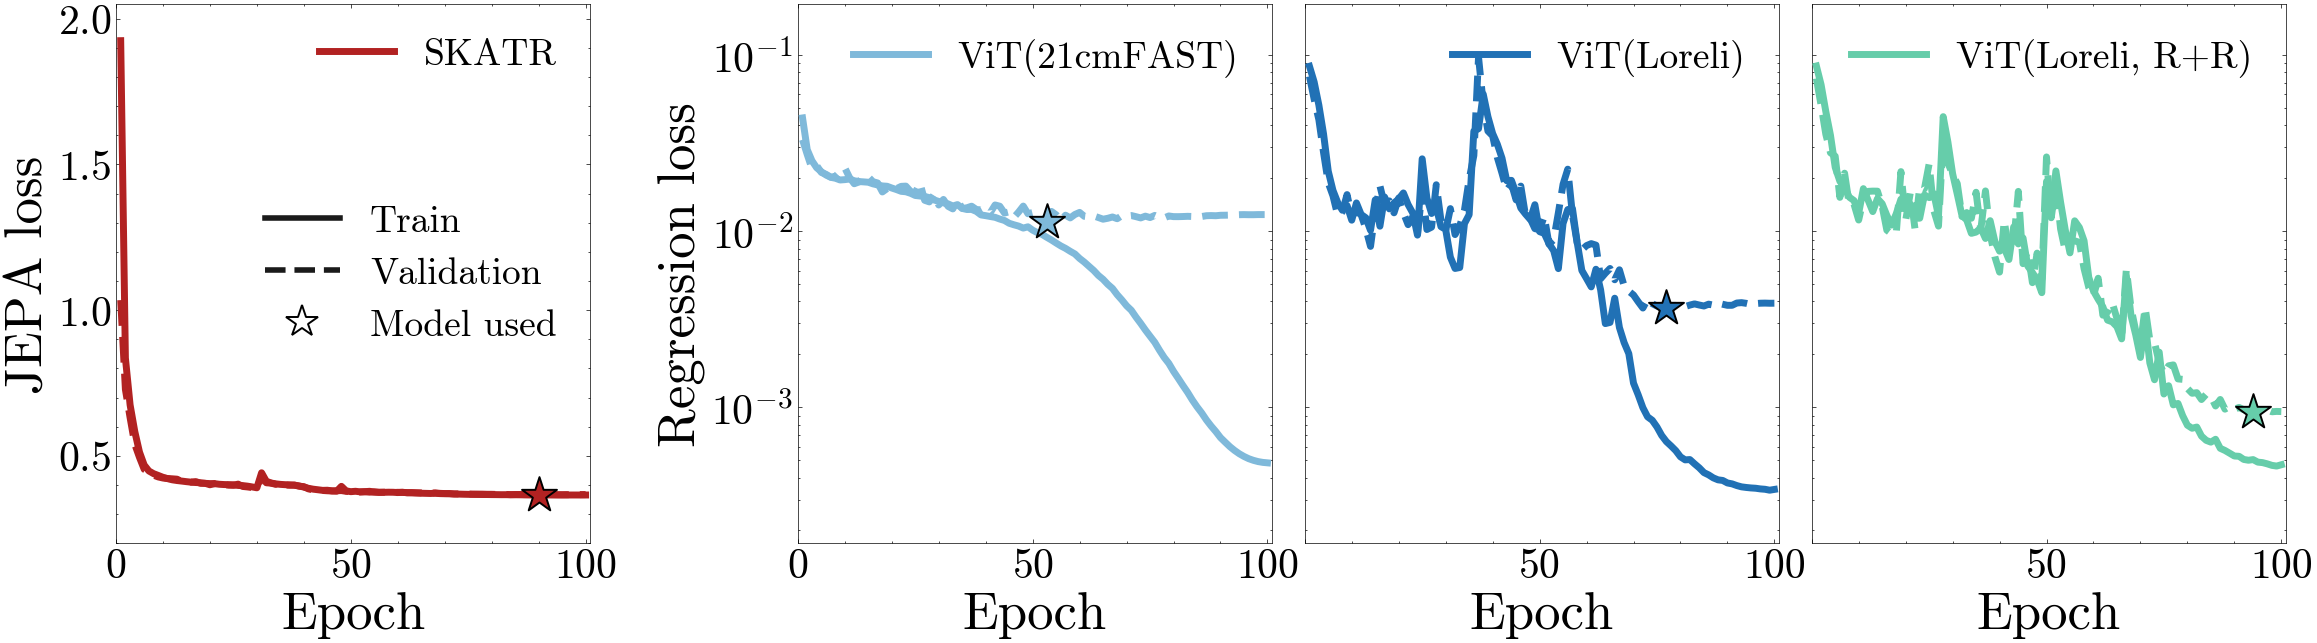

In [ ]:
# SKATR minimises a JEPA L1 loss in embedding space, while the supervised backbones minimise an L2 regression loss.
# The star marks the best-validation epoch, which is the checkpoint used downstream.

LBL, TICK, LEG = 38, 30, 27

fig = plt.figure(figsize=(28, 7))
gs = fig.add_gridspec(1, 5, width_ratios=[1, 0.30, 1, 1, 1], wspace=0.08)
axes = [fig.add_subplot(gs[0, 0])] + [fig.add_subplot(gs[0, c]) for c in (2, 3, 4)]

for ax, (label, tb, color) in zip(axes, curves):
    t, v = tb["epoch_loss_train"], tb["epoch_loss_val"]
    ep = np.arange(1, t.size + 1)
    ax.plot(ep, t, color=color, ls="-",  lw=5, zorder=3)
    ax.plot(ep, v, color=color, ls="--", lw=5, zorder=3)
    i = int(v.argmin())
    ax.scatter([i + 1], [v[i]], marker="*", s=700, color=color,
               edgecolors="black", linewidths=1.4, zorder=6)
    ax.set_xlabel("Epoch", fontsize=LBL)
    ax.set_xlim(0, 101)
    ax.set_xticks([0, 50, 100])
    ax.tick_params(axis="both", which="major", labelsize=TICK)
    ax.grid(False)
    ax.legend(handles=[Line2D([0], [0], color=color, lw=5, label=label)],
              fontsize=LEG, frameon=False, loc="upper right")

axes[0].set_ylim(0.2, 2.05)
axes[0].set_ylabel("JEPA loss", fontsize=LBL)

sup = np.concatenate([np.concatenate([tb["epoch_loss_train"], tb["epoch_loss_val"]])
                      for _, tb, _ in curves[1:]])
for ax in axes[1:]:
    ax.set_yscale("log")
    ax.set_ylim(sup.min() / 2, sup.max() * 2)
axes[1].set_ylabel("Regression loss", fontsize=LBL)
for ax in axes[2:]:
    ax.tick_params(axis="y", labelleft=False)
    ax.set_xticklabels(["", "50", "100"])

axes[0].add_artist(axes[0].get_legend())
axes[0].legend(handles=[
    Line2D([0], [0], color=truth_color, lw=4, ls="-",  label="Train"),
    Line2D([0], [0], color=truth_color, lw=4, ls="--", label="Validation"),
    Line2D([0], [0], color="white", marker="*", ms=24, ls="none",
           markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.4,
           label="Model used"),
], fontsize=LEG, frameon=False, loc="center right")

plt.savefig(f"{FIGDIR}/loss_curves_best_epoch.pdf", bbox_inches="tight")
plt.show()